# Pre-entrega 2: Corpus preprocesado listo para modelado

**Data Science III: NLP & Deep Learning aplicado a Ciencia de Datos**
**Alumno:** Lucas Nahuel Julian
**Dataset:** AG News (provisto por la cátedra): noticias en inglés de 4 clases (World, Sports, Business, Sci_Tech).

### Objetivo
Construir un pipeline de preprocesamiento (Regex + normalización + lematización con SpaCy) y validar
la calidad del corpus con un EDA técnico: longitud de los documentos y percentil 95, distribución de
clases, palabras más frecuentes, stop-words y N-gramas.

### Estructura del notebook
1. Carga de librerías
2. Carga del dataset (train y test)
3. EDA inicial sobre el texto crudo
4. Stop-words y N-gramas sobre el texto crudo (diagnóstico)
5. Pipeline de preprocesamiento
6. EDA técnico sobre el corpus preprocesado
7. Conclusiones

## **1. Carga de librerías**
Se importan las librerías del curso: re para expresiones regulares, pandas y numpy para manejar los
datos, matplotlib/seaborn para gráficos, CountVectorizer de scikit-learn para contar N-gramas y
spacy con el modelo en_core_web_sm para la lematización en inglés.

In [1]:
import re
import warnings

import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer

from transformers import BertTokenizer

import spacy
nlp = spacy.load("en_core_web_sm")

C:\Users\lucas\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## **2. Carga del dataset**

Se usa la misma lógica del script cargar_dataset.py de la cátedra: se leen los dos archivos que ya vienen
separados (ag_news_train.csv y ag_news_test.csv), cada uno con las columnas text y label.
El conjunto de test no se usa para tomar decisiones: todo el análisis se hace sobre train y al test solo
se le aplica el mismo pipeline al final.

In [2]:
# Cambiá a "bbc_news" si preferís artículos largos.
DATASET = "ag_news"            # opciones: "ag_news" | "bbc_news"
BASE = Path("../data")  # carpeta donde está este script


def cargar(dataset: str = DATASET):
    """Devuelve (train_df, test_df) con columnas: text, label."""
    tr = pd.read_csv(BASE / f"{dataset}_train.csv")
    te = pd.read_csv(BASE / f"{dataset}_test.csv")
    return tr, te


if __name__ == "__main__":
    train_df, test_df = cargar()
    print(f"Dataset: {DATASET}")
    print(f"Train: {train_df.shape} | Test: {test_df.shape}")
    print("Clases:", sorted(train_df['label'].unique()))
    print(train_df.head())

Dataset: ag_news
Train: (8000, 2) | Test: (2000, 2)
Clases: ['Business', 'Sci_Tech', 'Sports', 'World']
                                                text     label
0  Red Hat Appoints New CFO. September 2, 2004 --...  Sci_Tech
1  Sprint, SBC In Hotspot Roaming Deal. Sprint an...  Sci_Tech
2  Radio Outage Grounds West Coast Flights. Airpo...  Business
3  Hollywood lawsuits to strike Net pirates. Holl...  Sci_Tech
4  Custis Takes Control. Family and Tony Robbins ...    Sports


Se cargaron 8.000 noticias de entrenamiento y 2.000 de test, con las 4 clases esperadas.

## **3. EDA inicial sobre el texto crudo**

Antes de limpiar, se mira el texto tal como viene para saber qué problemas tiene. Primero se tokeniza todo
el corpus de train con una regex simple y se cuentan las palabras más frecuentes.

In [3]:
# Tokenizar todo el corpus

def tokens_regex(text):
    return re.findall(r'\b\w+\b', str(text).lower(), flags=re.UNICODE)

tokens = []

for text in train_df['text']:
    tokens.extend(tokens_regex(text))

# Top 50 palabras más frecuentes
freq = Counter(tokens)

top50 = pd.DataFrame(
    freq.most_common(50),
    columns=['palabra', 'frecuencia']
)


Se calcula la longitud de cada noticia (caracteres y palabras) y se busca ruido de formato: etiquetas o
entidades HTML, URLs y emails.

Descriptivos de longitud:


,n_caracteres,n_palabras
count,8000.0,8000.0
mean,236.7,39.7
std,64.9,11.2
min,100.0,14.0
25%,196.0,33.0
50%,232.0,39.0
75%,266.0,45.0
max,995.0,162.0


Porcentaje con ruido de formato: {'contiene_html': 5.2, 'contiene_url': 3.2, 'contiene_email': 0.0}


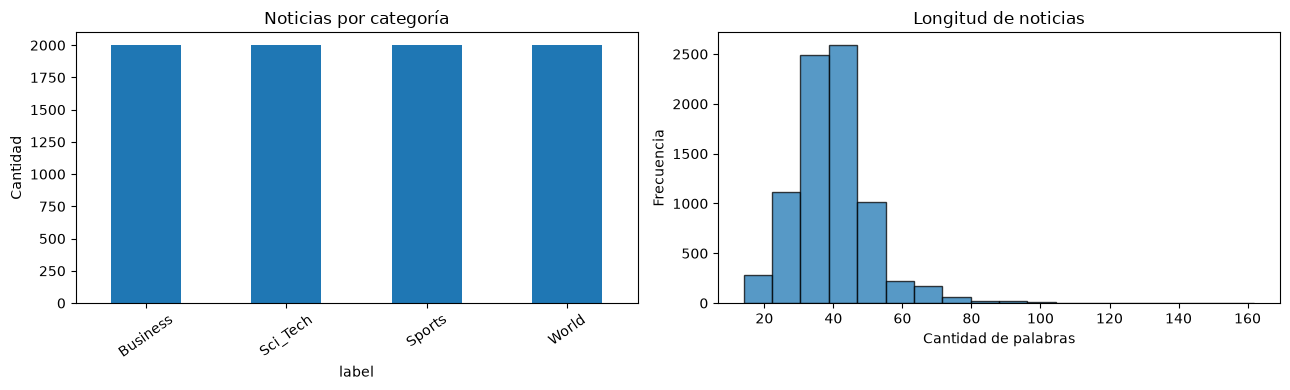

In [4]:
# Tokenización de palabras aproximada para EDA: usa expresiones Unicode.
# Conjunto de entrenamiento

train_df['n_caracteres'] = train_df.text.str.len()
train_df['n_palabras'] = train_df.text.map(lambda s: len(tokens_regex(s)))
train_df['contiene_html'] = train_df.text.str.contains(r'<[^>]+>&lt;&gt;#\d+;|\bquot;|\bamp;', regex=True)
train_df['contiene_url'] = train_df.text.str.contains(r'https?://|www\.|\b\w+\.(?:com|net|org)\b', regex=True)
train_df['contiene_email'] = train_df.text.str.contains(r'\b[\w.+-]+@[\w.-]+\.[a-zA-Z]{2,}\b', regex=True)

print('Descriptivos de longitud:')
display(train_df[['n_caracteres', 'n_palabras']].describe().round(1))
print('Porcentaje con ruido de formato:', (train_df[['contiene_html', 'contiene_url', 'contiene_email']].mean() * 100).round(1).to_dict())

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
train_df['label'].value_counts().sort_index().plot.bar(ax=axs[0], title='Noticias por categoría')
axs[0].set_ylabel('Cantidad'); axs[0].tick_params(axis='x', rotation=35)
axs[1].hist(train_df['n_palabras'], bins=18, edgecolor='black', alpha=.75)
axs[1].set(title='Longitud de noticias', xlabel='Cantidad de palabras', ylabel='Frecuencia')
plt.tight_layout(); plt.show()

**Observaciones:**
- Las noticias son cortas (título + primer párrafo): en promedio unas 40 palabras.
- Hay noticias de las 4 categorías en cantidades iguales.
- Aproximadamente un 5% tiene restos de HTML y un 3% tiene URLs o dominios web. No hay emails.
- Aunque el dataset viene bastante limpio, tiene ruido que hay que tratar.

In [5]:
p95 = np.percentile(train_df['n_palabras'], 95)

print(f"Percentil 95: {p95:.0f} palabras")

Percentil 95: 59 palabras


Este percentil 95 (59 palabras) está calculado sobre el texto **crudo**. Más adelante se recalcula sobre el
texto preprocesado, que es el que realmente va a entrar al modelo.

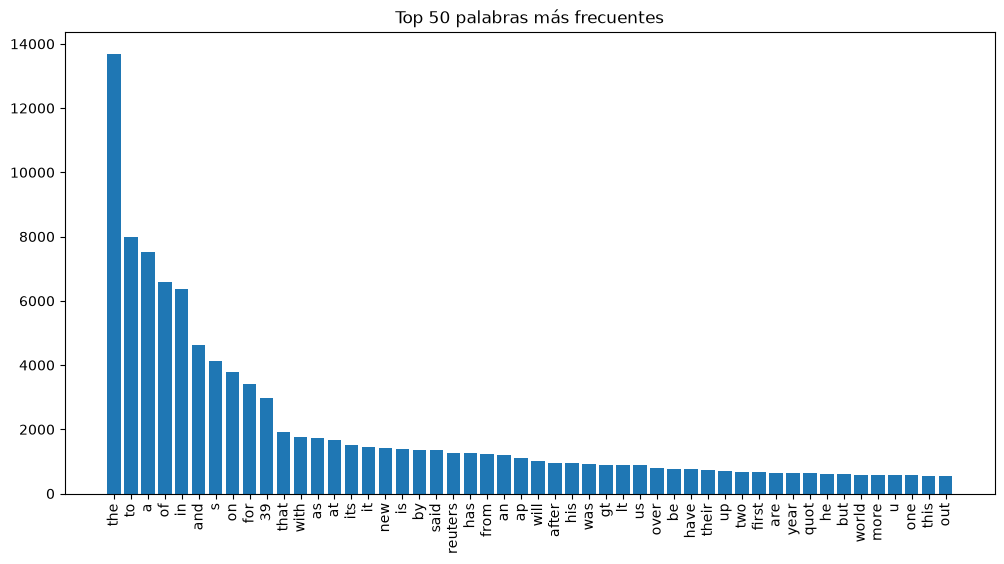

In [6]:
plt.figure(figsize=(12,6))

plt.bar(
    top50['palabra'],
    top50['frecuencia']
)

plt.xticks(rotation=90)
plt.title('Top 50 palabras más frecuentes')
plt.show()

El top 50 crudo está dominado por artículos y preposiciones (the, to, a, of, in). Este es el error que
menciona la consigna: si se hace una nube de palabras o un ranking sin limpiar, solo aparecen palabras
sin valor informativo.

## **4. Stop-words y N-gramas sobre el texto crudo (diagnóstico)**

Se marca cuáles de las 50 palabras más frecuentes son stop-words según la lista de scikit-learn.

In [7]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

top50['es_stopword'] = top50['palabra'].isin(
    ENGLISH_STOP_WORDS
)

display(top50)

print(
    "Cantidad de stopwords:",
    top50['es_stopword'].sum()
)


,palabra,frecuencia,es_stopword
0,the,13697,True
1,to,7975,True
2,a,7532,True
3,of,6578,True
4,in,6363,True
5,and,4637,True
6,s,4131,False
7,on,3772,True
8,for,3410,True
9,39,2961,False


Cantidad de stopwords: 38


38 de las 50 palabras más frecuentes son stop-words. Ahora se miran las que no lo son:

In [8]:
#Del top50, eliminar las stopwords más frecuentes para ver qué palabras quedan.

top50[
    ~top50['es_stopword']
]

,palabra,frecuencia,es_stopword
6,s,4131,False
9,39,2961,False
16,new,1420,False
19,said,1352,False
20,reuters,1272,False
24,ap,1117,False
29,gt,887,False
30,lt,885,False
40,year,644,False
41,quot,636,False


Entre las palabras que no son stop-words aparece mucho ruido:
- 39 y s vienen de #39;s, que es un apóstrofo mal codificado.
- quot, lt, gt son entidades HTML (quot;, &lt;, &gt;).
- reuters y ap son las firmas de las agencias de noticias, no el tema de la noticia.
- u viene de U.S. partido en letras sueltas.

Con esta información se arma un conjunto de stop-words para el EDA que suma las stop-words detectadas y
estas palabras de ruido.

In [9]:
# Conjunto de stopwords para EDA: Tras el análisis, se concluye en usar las stopwords de Spacy + algunas palabras de ruido que se identificaron en el análisis.
STOPWORDS_EDA = (
    set(top50.loc[top50['es_stopword'], 'palabra'])
    | {
        'www', 'http', 'https', 'com', 'net', 'org', 'www.', '.com', '.net', '.org','afp','fullquote','href','quickinfo','aspx','ticker','ap','gt','lt','39','s','u','quot','quote','co','size','font','verdana','serif','sans','arial','helvetica','ms'
    }
)

print(f"Stopwords totales: {len(STOPWORDS_EDA)}")

Stopwords totales: 71


Con estas stop-words se calculan los bigramas y trigramas más frecuentes sobre el texto crudo.

In [10]:
vectorizer = CountVectorizer(
    ngram_range=(2, 2),
    stop_words=list(STOPWORDS_EDA),
    min_df=2
)

X = vectorizer.fit_transform(train_df['text'])

frecuencias = X.sum(axis=0).A1

bigramas = pd.DataFrame({
    "bigrama": vectorizer.get_feature_names_out(),
    "frecuencia": frecuencias
})

top20_bigramas = (
    bigramas
    .sort_values("frecuencia", ascending=False)
    .head(20)
)

display(top20_bigramas)

,bigrama,frecuencia
9999,new york,419
12609,reuters reuters,261
10546,oil prices,185
16048,united states,167
17414,york reuters,158
11717,prime minister,139
15327,third quarter,135
14957,target stocks,131
7390,investor reuters,131
13013,said thursday,101


In [11]:
vectorizer = CountVectorizer(
    ngram_range=(3, 3),
    stop_words=list(STOPWORDS_EDA),
    min_df=2
)

X = vectorizer.fit_transform(train_df['text'])

frecuencias = X.sum(axis=0).A1

trigramas = pd.DataFrame({
    "trigrama": vectorizer.get_feature_names_out(),
    "frecuencia": frecuencias
})

top20_trigramas = (
    trigramas
    .sort_values("frecuencia", ascending=False)
    .head(20)
)

display(top20_trigramas)

,trigrama,frecuencia
3388,new york reuters,158
2257,inc investor reuters,56
690,boston red sox,36
1126,corp investor reuters,33
6200,york reuters stocks,29
5463,third quarter profit,28
807,canadian press canadian,26
4799,securities exchange commission,26
4047,prime minister ariel,26
4016,press canadian press,26


Diagnóstico de los N-gramas crudos: aparecen entidades reales (new york, oil prices, prime minister,
boston red sox), pero también mucho ruido: reuters reuters, york reuters, investor reuters,
target stocks, face color 666666 (restos de etiquetas HTML) y combinaciones con días de la semana
(said thursday, said monday). Esto confirma que hace falta un pipeline de limpieza antes de modelar.

## **5. Pipeline de preprocesamiento**

A partir del diagnóstico anterior se construye el pipeline. La función clean_text() aplica la limpieza
con Regex y la normalización:
1. Corrige el apóstrofo mal codificado (#39;).
2. Elimina etiquetas HTML, incluidas las que vienen escapadas (&lt;A HREF=...&gt;).
3. Elimina entidades HTML (quot;, amp;) usando límites de palabra (\b) para no cortar palabras.
4. Elimina URLs, emails y dominios web (redhat.com).
5. Elimina las firmas de las agencias de noticias ((Reuters), (AP), Reuters -) y el texto fijo
   (Quote, Profile, Research) que Reuters agrega junto a las empresas.
6. Elimina números, pasa todo a minúsculas y elimina espacios múltiples.

In [12]:
def clean_text(text):

    text = str(text)

    # Apóstrofo mal codificado: "Europe #39;s" -> "Europe's"
    text = re.sub(r'\s?#39;', "'", text)

    # HTML escapado: convertimos &lt; y &gt; en < y > para poder borrar las etiquetas
    text = text.replace('&lt;', '<').replace('&gt;', '>')

    # Etiquetas HTML (también las que quedaron cortadas al final del texto)
    text = re.sub(r'<[^>]*>?', ' ', text)

    # Entidades HTML, ahora con límite de palabra (\b) para no cortar palabras
    text = re.sub(r'&amp;|\bquot;|\bamp;|\blt;|\bgt;|#\d+;', ' ', text)

    # URLs, emails y dominios (redhat.com, washingtonpost.com)
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'\b[\w.+-]+@[\w.-]+\.[a-zA-Z]{2,}\b', ' ', text)
    text = re.sub(r'\b\w+\.(com|net|org)\b', ' ', text)

    # Texto fijo de Reuters junto a las empresas: "(GE.N: Quote, Profile, Research)"
    text = re.sub(r'\([^)]*Quote, Profile, Research\)', ' ', text)

    # Firmas de agencias de noticias: "(Reuters)", "(AP)", "Reuters - "
    text = re.sub(r'\((Reuters|AP|AFP|CP|Canadian Press|Sports Network)\)', ' ', text)
    text = re.sub(r'\b(Reuters|AP|AFP) - ', ' ', text)

    # "U.S." -> "USA" para que no se pierda como letras sueltas
    text = text.replace('U.S.', 'USA')

    # Números
    text = re.sub(r'\d+', ' ', text)

    # Minúsculas
    text = text.lower()

    # Espacios múltiples
    text = re.sub(r'\s+', ' ', text)

    return text.strip()

Stop-words. Se usa la lista completa de stop-words de SpaCy más las palabras de ruido detectadas
en el EDA (STOPWORDS_EDA), pero se conservan las negaciones (no, not, never, nor, without,
against), porque cambian el sentido de la frase ("the company did not confirm" no es lo mismo que
"the company confirmed").

También se agregan los nombres de agencias y los días de la semana: aparecen en todas las categorías y
no ayudan a saber de qué trata la noticia.

In [13]:
NEGACIONES = {'no', 'not', 'never', 'nor', 'without', 'against', 'none', 'nothing', "n't"}

DIAS = {'monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday',
        'yesterday', 'today'}

STOPWORDS_FINAL = (nlp.Defaults.stop_words | STOPWORDS_EDA | DIAS | {'reuters', "'s"}) - NEGACIONES

print(f"Stop-words finales: {len(STOPWORDS_FINAL)}")
print("Negaciones que se conservan:", NEGACIONES)

Stop-words finales: 360
Negaciones que se conservan: {'nor', 'none', 'not', 'without', 'nothing', "n't", 'never', 'against', 'no'}


La función preprocess_text() integra todo el pipeline: llama a clean_text(), procesa el texto con
SpaCy, descarta puntuación, espacios, stop-words y tokens de una sola letra, y devuelve los lemas
(la forma base de cada palabra: announced - announce, flights - flight).

In [14]:
def preprocess_text(text):

    text = clean_text(text)

    doc = nlp(text)

    tokens = []

    for token in doc:

        if token.is_punct:
            continue

        if token.is_space:
            continue

        lema = token.lemma_.lower()

        # "didn't" -> SpaCy separa "did" + "n't"; guardamos la negación como "not"
        if lema == "n't":
            lema = "not"

        if lema in STOPWORDS_FINAL:
            continue

        if len(lema) < 2:
            continue

        tokens.append(lema)

    return " ".join(tokens)

Prueba rápida con frases de ejemplo, incluida una con HTML escapado y una negación:

In [15]:
ejemplos = [
    "Officials did not confirm the deal on Monday (Reuters).",
    "Officials confirmed the deal.",
    "Federer wins the championship in Washington.",
    'PepsiCo Inc. &lt;A HREF="http://www.investor.reuters.com/FullQuote.aspx?ticker=PEP.N"&gt;PEP.N&lt;/A&gt; said profit rose.',
]

for frase in ejemplos:
    print("ORIGINAL :", frase)
    print("PROCESADO:", preprocess_text(frase))
    print()

ORIGINAL : Officials did not confirm the deal on Monday (Reuters).
PROCESADO: official not confirm deal

ORIGINAL : Officials confirmed the deal.
PROCESADO: official confirm deal

ORIGINAL : Federer wins the championship in Washington.
PROCESADO: federer win championship washington

ORIGINAL : PepsiCo Inc. &lt;A HREF="http://www.investor.reuters.com/FullQuote.aspx?ticker=PEP.N"&gt;PEP.N&lt;/A&gt; said profit rose.
PROCESADO: pepsico inc pep.n profit rise



El pipeline elimina el HTML y la firma de la agencia, lematiza y
mantiene el not, de modo que las dos primeras frases quedan distintas.

Se aplica a la columna text de train y test (la misma función para los dos, sin "aprender" nada del
test).

In [16]:
train_df["text_preprocessed"] = train_df["text"].apply(preprocess_text)
test_df["text_preprocessed"] = test_df["text"].apply(preprocess_text)

In [17]:
train_df[
    ["text", "text_preprocessed"]
].head(10)

,text,text_preprocessed
0,"Red Hat Appoints New CFO. September 2, 2004 --...",red hat appoint new cfo september web host ind...
1,"Sprint, SBC In Hotspot Roaming Deal. Sprint an...",sprint sbc hotspot roam deal sprint sbc commun...
2,Radio Outage Grounds West Coast Flights. Airpo...,radio outage ground west coast flight airport ...
3,Hollywood lawsuits to strike Net pirates. Holl...,hollywood lawsuit strike pirate hollywood stud...
4,Custis Takes Control. Family and Tony Robbins ...,custis control family tony robbin mature mold ...
5,CA execs can keep bonuses--for now. Computer A...,exec bonus computer associate international sh...
6,"WorldCom, Microsoft cases before EU court. Two...",worldcom microsoft case eu court european unio...
7,EU Court Overturns Bar on Merger (Reuters). Re...,eu court overturn bar merger european commissi...
8,Homer-happy Mariners end skid. A four-pitch se...,homer happy mariner end skid pitch sequence fi...
9,Philip Morris lab discovered passive smoking r...,philip morris lab discover passive smoking ris...


Comparación entre el texto original y el procesado en las primeras 3 noticias:

In [18]:
for i in range(3):

    print("ORIGINAL:")
    print(train_df.iloc[i]["text"])

    print("\nPROCESADO:")
    print(train_df.iloc[i]["text_preprocessed"])

    print("\n" + "="*80 + "\n")

ORIGINAL:
Red Hat Appoints New CFO. September 2, 2004 -- (WEB HOST INDUSTRY REVIEW) -- Linux distributor Red Hat (redhat.com) announced on Thursday that it has appointed Charles E. Peters, Jr.

PROCESADO:
red hat appoint new cfo september web host industry review linux distributor red hat announce appoint charles e. peters jr


ORIGINAL:
Sprint, SBC In Hotspot Roaming Deal. Sprint and SBC Communications Friday announced a two-way roaming deal that will enable the customers of each vendor to access the hotspots run by the other.

PROCESADO:
sprint sbc hotspot roam deal sprint sbc communication announce way roaming deal enable customer vendor access hotspot run


ORIGINAL:
Radio Outage Grounds West Coast Flights. Airport operations were back to normal early Wednesday following a radio failure at a Federal Aviation Administration control facility that tied up travelers for hours.

PROCESADO:
radio outage ground west coast flight airport operation normal early follow radio failure federal 

El texto procesado queda en minúsculas, sin puntuación, números, dominios ni stop-words, y con las
palabras lematizadas (appointed - appoint, operations - operation).

In [19]:
# Guardamos el corpus preprocesado para los próximos módulos
train_df[["text_preprocessed", "label"]].to_csv(BASE / "ag_news_train_clean.csv", index=False)
test_df[["text_preprocessed", "label"]].to_csv(BASE / "ag_news_test_clean.csv", index=False)

print("Archivos guardados en", BASE)

Archivos guardados en ..\data


## **6. EDA técnico sobre el corpus preprocesado**

### 6.1 Cantidad de tokens por documento y percentil 95
El percentil 95 de la cantidad de tokens va a ser el max_len de los modelos las
secuencias más largas se cortan y las más cortas se completan con padding.

In [20]:
train_df['n_tokens'] = train_df['text_preprocessed'].map(lambda s: len(s.split()))
test_df['n_tokens'] = test_df['text_preprocessed'].map(lambda s: len(s.split()))

p95_tokens = np.percentile(train_df['n_tokens'], 95)

print(train_df['n_tokens'].describe().round(1))
print(f"\nPercentil 95: {p95_tokens:.0f} tokens -> max_len")
print(f"Noticias que superan el max_len: {(train_df['n_tokens'] > p95_tokens).mean() * 100:.1f}%")

count    8000.0
mean       22.3
std         5.7
min         5.0
25%        19.0
50%        22.0
75%        26.0
max        70.0
Name: n_tokens, dtype: float64

Percentil 95: 31 tokens -> max_len
Noticias que superan el max_len: 4.8%


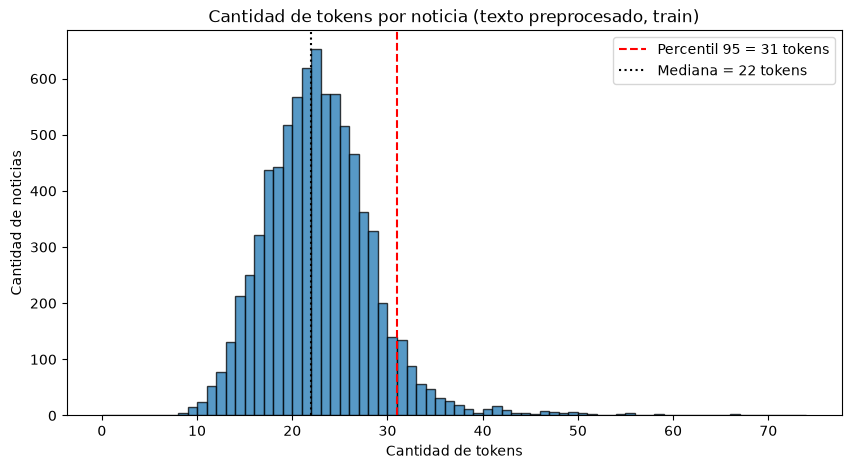

In [21]:
plt.figure(figsize=(10, 5))

plt.hist(train_df['n_tokens'], bins=range(0, 75), edgecolor='black', alpha=.75)
plt.axvline(p95_tokens, color='red', linestyle='--', label=f'Percentil 95 = {p95_tokens:.0f} tokens')
plt.axvline(train_df['n_tokens'].median(), color='black', linestyle=':',
            label=f"Mediana = {train_df['n_tokens'].median():.0f} tokens")

plt.title('Cantidad de tokens por noticia (texto preprocesado, train)')
plt.xlabel('Cantidad de tokens')
plt.ylabel('Cantidad de noticias')
plt.legend()
plt.savefig('hist_tokens.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Categorías que tienen las noticias más largas.
train_df.groupby('label')['n_tokens'].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
Business,2000.0,22.6,4.9,5.0,19.0,23.0,26.0,60.0
Sci_Tech,2000.0,22.1,6.7,6.0,18.0,22.0,25.0,70.0
Sports,2000.0,21.4,5.0,9.0,18.0,21.0,24.0,50.0
World,2000.0,23.1,6.0,8.0,19.0,23.0,26.0,58.0


El histograma tiene forma de campana: la mayoría de las noticias tiene entre 15 y 30 tokens después del
preprocesamiento (antes eran unas 40 palabras). El percentil 95 se usa como max_len porque cubre el 95% de
las noticias completas sin agregar padding innecesario. Las 4 categorías tienen longitudes parecidas.

### 6.2 Distribución de clases en train y test

In [23]:
dist_clases = pd.DataFrame({
    'train': train_df['label'].value_counts(),
    'test': test_df['label'].value_counts()
})

dist_clases['train %'] = (dist_clases['train'] / dist_clases['train'].sum() * 100).round(1)
dist_clases['test %'] = (dist_clases['test'] / dist_clases['test'].sum() * 100).round(1)

display(dist_clases)

,train,test,train %,test %
label,,,,
Business,2000,500,25.0,25.0
Sci_Tech,2000,500,25.0,25.0
Sports,2000,500,25.0,25.0
World,2000,500,25.0,25.0


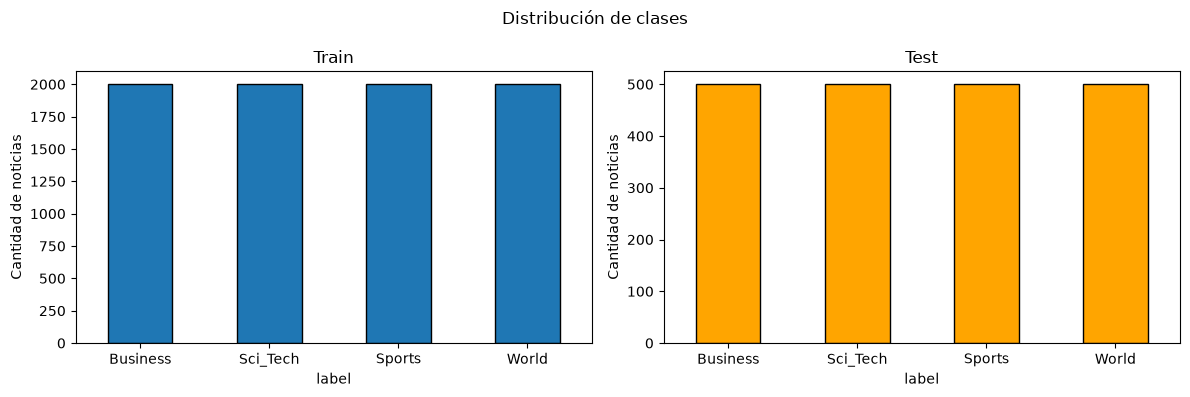

In [24]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

dist_clases['train'].plot.bar(ax=axs[0], title='Train', edgecolor='black')
dist_clases['test'].plot.bar(ax=axs[1], title='Test', color='orange', edgecolor='black')

for ax in axs:
    ax.set_ylabel('Cantidad de noticias')
    ax.tick_params(axis='x', rotation=0)

plt.suptitle('Distribución de clases')
plt.tight_layout()
plt.savefig('distribucion_clases.png', dpi=150, bbox_inches='tight')
plt.show()

El dataset está perfectamente balanceado: 25% de noticias por clase en train y en test. No hace falta
balancear las clases y la accuracy es una métrica válida (aunque conviene mirar también F1 y la matriz de
confusión).

### 6.3 Top 50 palabras más frecuentes y verificación de stop-words

In [25]:
tokens_clean = []

for text in train_df['text_preprocessed']:
    tokens_clean.extend(text.split())

freq_clean = Counter(tokens_clean)

top50_clean = pd.DataFrame(
    freq_clean.most_common(50),
    columns=['palabra', 'frecuencia']
)

# Verificamos contra la lista estándar de stop-words de SpaCy
top50_clean['es_stopword'] = top50_clean['palabra'].isin(nlp.Defaults.stop_words)

print("Stop-words en el top 50 ANTES del pipeline:", top50['es_stopword'].sum())
print("Stop-words en el top 50 DESPUÉS del pipeline:", top50_clean['es_stopword'].sum())
print("Cuáles quedaron:", top50_clean.loc[top50_clean['es_stopword'], 'palabra'].tolist())

display(top50_clean)

Stop-words en el top 50 ANTES del pipeline: 38
Stop-words en el top 50 DESPUÉS del pipeline: 3
Cuáles quedaron: ['not', 'against', 'no']


,palabra,frecuencia,es_stopword
0,new,1432,False
1,year,849,False
2,not,799,True
3,company,650,False
4,world,608,False
5,win,573,False
6,report,549,False
7,game,544,False
8,oil,519,False
9,usa,516,False


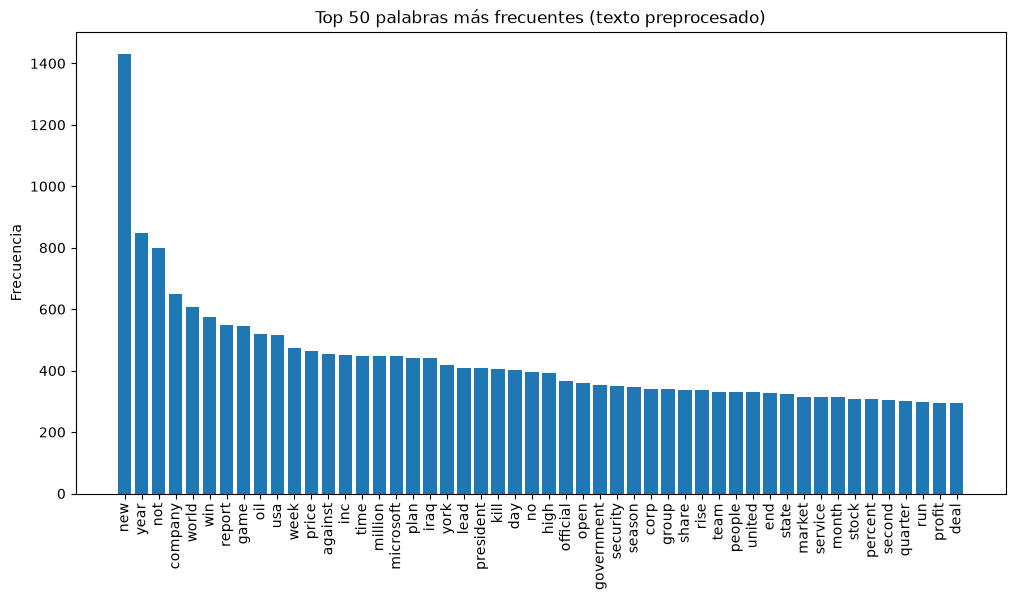

In [26]:
plt.figure(figsize=(12, 6))

plt.bar(top50_clean['palabra'], top50_clean['frecuencia'])

plt.xticks(rotation=90)
plt.title('Top 50 palabras más frecuentes (texto preprocesado)')
plt.ylabel('Frecuencia')
plt.savefig('top50_palabras.png', dpi=150, bbox_inches='tight')
plt.show()

Antes del pipeline, 38 de las 50 palabras más frecuentes eran stop-words. Después solo quedan las
negaciones que se conservaron a propósito (not, no, against). El resto son palabras con contenido
temático: company, game, oil, microsoft, iraq, price. No aparecen restos de HTML (quot, lt, gt) ni
firmas de agencias.

### 6.4 Top 20 bigramas y trigramas sobre el texto preprocesado

In [27]:
vectorizer = CountVectorizer(ngram_range=(2, 2))

X = vectorizer.fit_transform(train_df['text_preprocessed'])

frecuencias = X.sum(axis=0).A1

bigramas_clean = pd.DataFrame({
    "bigrama": vectorizer.get_feature_names_out(),
    "frecuencia": frecuencias
})

top20_bigramas_clean = (
    bigramas_clean
    .sort_values("frecuencia", ascending=False)
    .head(20)
)

display(top20_bigramas_clean)

,bigrama,frecuencia
75804,new york,419
79260,oil price,197
120967,united states,166
88897,prime minister,139
93992,red sox,98
100091,san francisco,96
66164,los angeles,96
88224,president bush,93
129241,year old,87
72325,mobile phone,72


In [28]:
vectorizer = CountVectorizer(ngram_range=(3, 3))

X = vectorizer.fit_transform(train_df['text_preprocessed'])

frecuencias = X.sum(axis=0).A1

trigramas_clean = pd.DataFrame({
    "trigrama": vectorizer.get_feature_names_out(),
    "frecuencia": frecuencias
})

top20_trigramas_clean = (
    trigramas_clean
    .sort_values("frecuencia", ascending=False)
    .head(20)
)

display(top20_trigramas_clean)

,trigrama,frecuencia
88415,new york usa,43
15216,boston red sox,37
58661,high oil price,27
104360,prime minister ariel,26
152543,york usa stock,26
83103,minister ariel sharon,25
128603,state colin powell,22
119454,secretary state colin,22
103498,president george bush,21
103601,president vladimir putin,21


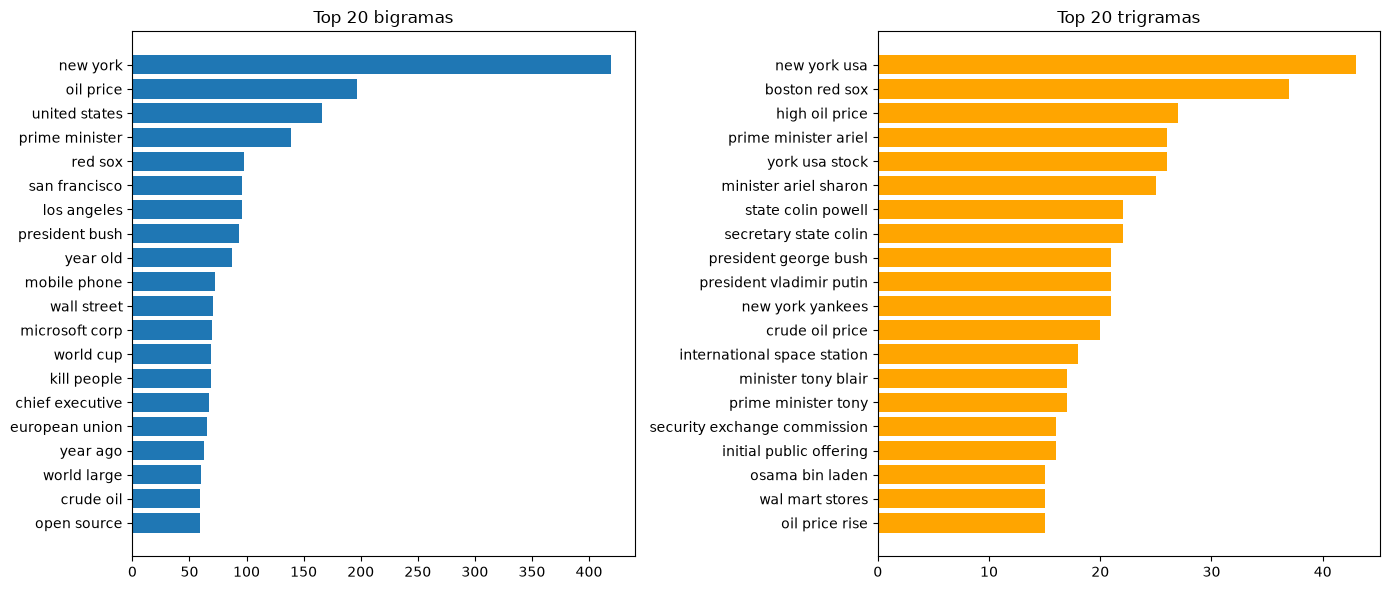

In [29]:
fig, axs = plt.subplots(1, 2, figsize=(14, 6))

axs[0].barh(top20_bigramas_clean['bigrama'], top20_bigramas_clean['frecuencia'])
axs[0].invert_yaxis()
axs[0].set_title('Top 20 bigramas')

axs[1].barh(top20_trigramas_clean['trigrama'], top20_trigramas_clean['frecuencia'], color='orange')
axs[1].invert_yaxis()
axs[1].set_title('Top 20 trigramas')

plt.tight_layout()
plt.savefig('ngramas.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Control final, búsqueda de n-gramas con ruido en el top 20 de bigramas y trigramas.
ruido = ['reuters', 'href', 'quot', 'lt', 'gt', 'com', 'www', 'http', 'profile', 'font', 'color']

for ngrama in list(top20_bigramas_clean['bigrama']) + list(top20_trigramas_clean['trigrama']):
    for r in ruido:
        if r in ngrama.split() or r == ngrama:
            print("Ruido encontrado:", ngrama)

print("Control terminado")

Control terminado


Ahora los n-gramas son entidades y expresiones del dominio: lugares (new york, united states),
política (prime minister, president bush), deportes (red sox, world cup) y economía (oil price,
wall street). No aparecen restos de HTML ni firmas de agencias, que en el texto crudo generaban
N-gramas como reuters reuters o face color 666666.
new york usa viene de noticias de bolsa que empiezan con "NEW YORK - U.S. stocks": no es ruido, pero
muestra que muchas noticias de Business arrancan igual.

Nota: como las stop-words se eliminan antes de contar, algunos N-gramas unen palabras que en el texto
original no estaban juntas (por ejemplo "secretary of state Colin Powell" - secretary state colin).

## **7. Conclusiones**

Aunque AG News se presenta como un dataset limpio, tiene ruido heredado de las
páginas web de donde se obtuvo: apóstrofos mal codificados (#39;), entidades HTML (quot;, &lt;,
&gt;), enlaces HTML escapados, firmas de agencias (Reuters, AP, AFP) y números. Sin limpiar, 38 de las 50
palabras más frecuentes eran stop-words.

El corpus está balanceado: 2.000 noticias por clase en train y 500 en test.

El preprocess_text() limpia el texto con Regex, normaliza
(minúsculas, sin números) y lematiza con SpaCy, quitando stop-words pero conservando las negaciones. Después
del pipeline solo 3 de las 50 palabras más frecuentes son stop-words (las negaciones conservadas) y los
N-gramas representan entidades reales del dominio, sin restos de HTML ni firmas de agencias.

El percentil 95 de tokens por noticia se usará como max_len, y el corpus limpio
queda guardado en ag_news_train_clean.csv y ag_news_test_clean.csv para los próximos módulos.